# NB HU38

In [6]:
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# librerias para procesamiento de archivos raster (TIFF), shapefiles y dataframes
%pip install numpy
%pip install pandas
%pip install geopandas
%pip install rasterio
%pip install --upgrade "pyarrow>=16.0.0"
%pip install "affine==2.4.0"

StatementMeta(, 0bf7312a-660e-49cc-a50e-b28806ea5dba, 29, Finished, Available, Finished, False)


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 63.7 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 14.0.2
    Not uninstalling pyarrow at /home/trusted-service-user/cluster-env/trident_env/lib/pyt

### HU-38 Calcular las correlaciones espaciales

In [ ]:
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# ETL HU-38 - CORRELACIONES ESPACIALES CONTRA TCHM DEL AÑO ACTUAL
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

from pathlib import Path
from datetime import datetime
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

from rasterio.mask import mask
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# FASE 1. CONFIGURACIÓN
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

ANIO_ACTUAL = datetime.now().year

BASE = Path("/lakehouse/default/Files")
RUTA_SHAPEFILE = BASE / "capas" / "ste.shp"

CARPETA_CONSOLIDADO = BASE / "CONSOLIDADO"
CARPETA_TCHM = CARPETA_CONSOLIDADO / "TCH_TCHM"

CARPETA_SALIDA = (
    CARPETA_CONSOLIDADO / "CORRELACIONES_ESPACIALES"
)
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)

print(f"[FASE 1/7] Año de referencia: {ANIO_ACTUAL}")
print(f"             Shapefile: {RUTA_SHAPEFILE}")


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# FASE 2. FUNCIONES DE IDENTIFICACIÓN
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(
        c for c in texto if not unicodedata.combining(c)
    )
    return re.sub(r"[^a-z0-9]", "", texto.lower())


# Alias ordenados desde los nombres más específicos.
# Esto evita confundir lluvias de periodos distintos.
ALIAS_VARIABLES = {
    "Lluvias (0 - 3 Meses)": [
        "LLUVIAS_0_-_3_MESES",
        "LLUVIAS_0_3_MESES",
        "LLUVIAS03MESES"
    ],
    "Lluvias 10d Ant.Cos": [
        "LLUVIAS_10D_ANTCOS",
        "LLUVIAS10DANTCOS"
    ],
    "Variedad_TIFF": ["VARIEDAD_TIFF"],
    "Semanas mad.": ["SEMANAS_MAD"],
    "Num.Riegos": ["NUMRIEGOS", "NUM_RIEGOS"],
    "Ton.Azucar": ["TONAZUCAR", "TON_AZUCAR"],
    "%Sac.Cana": ["SACCANA", "SAC_CANA"],
    "Lluvias": ["LLUVIAS"],
    "Corte": ["CORTE"],
    "Edad": ["EDAD"],
    "Rdto": ["RDTO", "RENDIMIENTO"],
    "TAHM": ["TAHM"],
    "TAH": ["TAH"],
    "Vejez": ["VEJEZ"]
}


def identificar_variable(nombre_archivo):
    """
    Identifica la variable usando el nombre del archivo,
    sin confundir años ni periodos de lluvia.
    """
    nombre = Path(nombre_archivo).stem

    # Eliminar el año inicial, por ejemplo 2017_.
    nombre_sin_anio = re.sub(
        r"^\d{4}[_-]+", "", nombre
    )
    nombre_norm = normalizar(nombre_sin_anio)

    for variable, alias_lista in ALIAS_VARIABLES.items():
        for alias in alias_lista:
            if normalizar(alias) == nombre_norm:
                return variable

    return "OTRA"


def obtener_anio(nombre_archivo):
    coincidencia = re.match(
        r"^(\d{4})[_-]", Path(nombre_archivo).stem
    )
    return int(coincidencia.group(1)) if coincidencia else None


def nombre_columna(ruta):
    """
    Mantiene año y variable en el nombre para diferenciar
    los TIFF de distintos años.
    """
    return re.sub(
        r"[^A-Za-z0-9]+", "_", Path(ruta).stem
    ).strip("_")


def calcular_pearson(a, b):
    """
    Calcula Pearson con pares de píxeles válidos.
    """
    a = np.asarray(a, dtype="float64").ravel()
    b = np.asarray(b, dtype="float64").ravel()

    validos = np.isfinite(a) & np.isfinite(b)
    a = a[validos]
    b = b[validos]

    n = len(a)

    if n < 2:
        return np.nan, n

    if np.std(a) == 0 or np.std(b) == 0:
        return np.nan, n

    return float(np.corrcoef(a, b)[0, 1]), n


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# FASE 3. VALIDAR ARCHIVOS Y CARGAR POLÍGONOS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

if not RUTA_SHAPEFILE.exists():
    raise FileNotFoundError(
        f"No se encontró el shapefile: {RUTA_SHAPEFILE}"
    )

gdf_lotes = gpd.read_file(RUTA_SHAPEFILE)

if gdf_lotes.empty:
    raise ValueError("El shapefile no contiene polígonos.")

if gdf_lotes.crs is None:
    raise ValueError(
        "El shapefile no tiene sistema de coordenadas definido."
    )

campos = {str(c).upper(): c for c in gdf_lotes.columns}

if "CODSIA" not in campos:
    raise ValueError(
        f"No se encuentra CODSIA. Campos: {list(gdf_lotes.columns)}"
    )

CAMPO_LOTE = campos["CODSIA"]

# Buscar el raster de referencia del año actual.
candidatos_tchm = sorted(
    p for p in CARPETA_TCHM.iterdir()
    if p.is_file()
    and p.suffix.lower() in (".tif", ".tiff")
    and normalizar(p.stem) == normalizar(f"TCHM_{ANIO_ACTUAL}")
)

if len(candidatos_tchm) != 1:
    raise ValueError(
        f"Se esperaba exactamente un TCHM_{ANIO_ACTUAL}.tif "
        f"en {CARPETA_TCHM}; encontrados: "
        f"{[p.name for p in candidatos_tchm]}"
    )

RUTA_TCHM = candidatos_tchm[0]

print(f"[FASE 3/7] Lotes cargados: {len(gdf_lotes)}")
print(f"             Referencia: {RUTA_TCHM.name}")


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# FASE 4. IDENTIFICAR TODOS LOS TIFF CONSOLIDADOS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

archivos_tiff = sorted(
    p for p in CARPETA_CONSOLIDADO.rglob("*")
    if p.is_file()
    and p.suffix.lower() in (".tif", ".tiff")
    and "_TEMP_ETL" not in p.parts
    and "CORRELACIONES_ESPACIALES" not in p.parts
)

# Excluir el raster TCHM de referencia de la lista comparativa.
archivos_comparar = [
    p for p in archivos_tiff
    if p.resolve() != RUTA_TCHM.resolve()
]

# Evitar que dos archivos con el mismo nombre de columna
# sobrescriban resultados en la matriz final.
columnas = [nombre_columna(p) for p in archivos_comparar]

if len(columnas) != len(set(columnas)):
    raise ValueError(
        "Hay TIFF con nombres repetidos en distintas carpetas. "
        "Se deben diferenciar por carpeta antes de generar la matriz."
    )

print(f"[FASE 4/7] TIFF encontrados: {len(archivos_tiff)}")
print(f"             TIFF por comparar: {len(archivos_comparar)}")


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# FASE 5. PREPARAR LOS POLÍGONOS Y EL TCHM
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

resultados = []

with rasterio.open(RUTA_TCHM) as raster_ref:

    if raster_ref.crs is None:
        raise ValueError("El TCHM no tiene CRS definido.")

    # Proyectar los lotes al CRS de referencia.
    lotes_ref = gdf_lotes.to_crs(raster_ref.crs)

    # Preparar cada geometría y recortar el TCHM una sola vez.
    lotes_preparados = []

    for _, lote in lotes_ref.iterrows():
        geometria = lote.geometry
        codsia = lote[CAMPO_LOTE]

        if geometria is None or geometria.is_empty:
            lotes_preparados.append(
                (codsia, None, None)
            )
            continue

        try:
            ref_recortado, _ = mask(
                raster_ref,
                [geometria],
                crop=True,
                filled=False
            )
            lotes_preparados.append(
                (codsia, geometria, ref_recortado[0])
            )
        except ValueError:
            # El lote no intersecta el TCHM.
            lotes_preparados.append(
                (codsia, geometria, None)
            )

print("[FASE 5/7] Polígonos y ventanas del TCHM preparados.")


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# FASE 6. CORRELACIÓN DE CADA TIFF POR LOTE
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

for indice, ruta_variable in enumerate(archivos_comparar, start=1):

    variable = identificar_variable(ruta_variable.name)
    anio_raster = obtener_anio(ruta_variable.name)
    columna = nombre_columna(ruta_variable)

    print(
        f"[FASE 6/7] TIFF {indice}/{len(archivos_comparar)}: "
        f"{ruta_variable.name}"
    )

    try:
        with rasterio.open(ruta_variable) as raster_var:

            if raster_var.crs is None:
                raise ValueError("El TIFF no tiene CRS definido.")

            # Alinear el TIFF con la cuadrícula exacta del TCHM.
            with WarpedVRT(
                raster_var,
                crs=raster_ref.crs,
                transform=raster_ref.transform,
                width=raster_ref.width,
                height=raster_ref.height,
                resampling=Resampling.nearest
            ) as raster_alineado:

                for codsia, geometria, ref_recortado in lotes_preparados:

                    registro = {
                        "CODSIA": codsia,
                        "anio_referencia": ANIO_ACTUAL,
                        "raster": ruta_variable.name,
                        "anio_raster": anio_raster,
                        "variable": variable,
                        "correlacion_pearson": np.nan,
                        "n_pixeles": 0
                    }

                    if geometria is None or ref_recortado is None:
                        resultados.append(registro)
                        continue

                    try:
                        var_recortado, _ = mask(
                            raster_alineado,
                            [geometria],
                            crop=True,
                            filled=False
                        )

                        var_valores = var_recortado[0]

                        if ref_recortado.shape != var_valores.shape:
                            raise ValueError(
                                "Las ventanas no tienen igual dimensión."
                            )

                        # Excluir NoData de ambos rasters.
                        mascara_valida = (
                            ~np.ma.getmaskarray(ref_recortado)
                            & ~np.ma.getmaskarray(var_valores)
                        )

                        valores_ref = np.asarray(
                            ref_recortado.data
                        )[mascara_valida]

                        valores_var = np.asarray(
                            var_valores.data
                        )[mascara_valida]

                        correlacion, n_pixeles = calcular_pearson(
                            valores_ref,
                            valores_var
                        )

                        registro["correlacion_pearson"] = correlacion
                        registro["n_pixeles"] = n_pixeles

                    except ValueError as e:
                        warnings.warn(
                            f"Lote {codsia}, TIFF {ruta_variable.name}: {e}"
                        )

                    resultados.append(registro)

    except Exception as e:
        warnings.warn(
            f"No se pudo procesar {ruta_variable.name}: {e}"
        )

        # Registrar el fallo para cada lote y continuar con los demás TIFF.
        for codsia, _, _ in lotes_preparados:
            resultados.append({
                "CODSIA": codsia,
                "anio_referencia": ANIO_ACTUAL,
                "raster": ruta_variable.name,
                "anio_raster": anio_raster,
                "variable": variable,
                "correlacion_pearson": np.nan,
                "n_pixeles": 0,
                "error": str(e)[:300]
            })


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# FASE 7. EXPORTAR DETALLE Y MATRIZ
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

df_detalle = pd.DataFrame(resultados)

ruta_detalle = (
    CARPETA_SALIDA
    / f"CORRELACIONES_TCHM_{ANIO_ACTUAL}_DETALLE.csv"
)

df_detalle.to_csv(
    ruta_detalle,
    index=False,
    encoding="utf-8-sig"
)

# Crear matriz: una fila por lote y una columna por TIFF.
if not df_detalle.empty:
    df_matriz = df_detalle.pivot_table(
        index="CODSIA",
        columns="raster",
        values="correlacion_pearson",
        aggfunc="first"
    ).reset_index()

    df_matriz.columns.name = None
else:
    df_matriz = pd.DataFrame(columns=["CODSIA"])

ruta_matriz = (
    CARPETA_SALIDA
    / f"CORRELACIONES_TCHM_{ANIO_ACTUAL}_MATRIZ.csv"
)

df_matriz.to_csv(
    ruta_matriz,
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "#+-" * 22)
print("HU-38 | RESUMEN DE CORRELACIONES ESPACIALES")
print("#+-" * 22)
print(f"Lotes: {len(gdf_lotes)}")
print(f"TIFF comparativos: {len(archivos_comparar)}")
print(f"Registros detalle: {len(df_detalle)}")
print(f"Archivo detalle: {ruta_detalle}")
print(f"Archivo matriz: {ruta_matriz}")

display(df_detalle.head(20))
display(df_matriz.head(20))


StatementMeta(, 97523a8f-59e0-4709-94a6-41fdf58db7a9, 16, Finished, Available, Finished, False)

[FASE 1/7] Año de referencia: 2026
             Shapefile: /lakehouse/default/Files/capas/ste.shp
[FASE 3/7] Lotes cargados: 9773
             Referencia: TCHM_2026.tif
[FASE 4/7] TIFF encontrados: 181
             TIFF por comparar: 180
[FASE 5/7] Polígonos y ventanas del TCHM preparados.
[FASE 6/7] TIFF 1/180: 2014_CORTE.tif
[FASE 6/7] TIFF 2/180: 2014_EDAD.tif
[FASE 6/7] TIFF 3/180: 2014_LLUVIAS_0_-_3_MESES.tif
[FASE 6/7] TIFF 4/180: 2014_LLUVIAS_10D_ANTCOS.tif
[FASE 6/7] TIFF 5/180: 2014_RDTO.tif
[FASE 6/7] TIFF 6/180: 2014_SACCANA.tif
[FASE 6/7] TIFF 7/180: 2014_SEMANAS_MAD.tif
[FASE 6/7] TIFF 8/180: 2014_TAH.tif
[FASE 6/7] TIFF 9/180: 2014_TAHM.tif
[FASE 6/7] TIFF 10/180: 2014_TONAZUCAR.tif
[FASE 6/7] TIFF 11/180: 2014_VARIEDAD_TIFF.tif
[FASE 6/7] TIFF 12/180: 2014_VEJEZ.tif
[FASE 6/7] TIFF 13/180: 2015_CORTE.tif
[FASE 6/7] TIFF 14/180: 2015_EDAD.tif
[FASE 6/7] TIFF 15/180: 2015_LLUVIAS_0_-_3_MESES.tif
[FASE 6/7] TIFF 16/180: 2015_LLUVIAS_10D_ANTCOS.tif
[FASE 6/7] TIFF 17/180: 20

SynapseWidget(Synapse.DataFrame, 12d6e6f4-cfe6-44f0-8201-8bf2f367ae1c)

SynapseWidget(Synapse.DataFrame, 1b70d692-63b2-43f9-99b1-00df8fc49137)

1. Resumen del archivo
Lotes analizados
20

Columnas de ráster
180

Celdas NULL
1.331
36,97 % de los valores

Valores negativos
1.144
31,78 % de los valores



2. ¿Por qué aparecen valores negativos?
Si el CSV contiene los coeficientes de correlación de Pearson entre cada ráster y TCHM_2026.tif, los valores negativos son válidos.
Valor	Interpretación
Cerca de +1	Relación positiva: ambas variables tienden a aumentar juntas.
Cerca de 0	No se observa una relación lineal clara.
Cerca de -1	Relación negativa: cuando una variable aumenta, la otra tiende a disminuir.
NULL	No fue posible calcular la correlación con los datos disponibles.

Por ejemplo, una correlación de -0,60 no significa que el ráster tenga valores negativos. Significa que existe una relación inversa entre sus valores y los del TCHM dentro del lote.

Importante: si el ráster contiene categorías, como VARIEDAD_TIFF o CORTE, una correlación de Pearson puede no ser la medida más adecuada, especialmente cuando los códigos representan categorías y no cantidades continuas.


3. ¿Por qué aparecen tantos NULL?
Las causas más probables en tu procesamiento son:
- Sin píxeles válidos coincidentes: el lote no tiene datos útiles en uno de los dos rásteres.
- Valores NoData: el ráster contiene píxeles sin información válida dentro del polígono.
- Valores constantes: si todos los píxeles válidos de un ráster tienen el mismo valor dentro de un lote, la desviación estándar es cero y Pearson no se puede calcular.
- Muy pocos píxeles válidos: aunque matemáticamente pueda calcularse una correlación con dos pares, el resultado no sería estadísticamente confiable.


##### HU-39 Generar el reporte de calidad de datos     
 Este notebook tiene dos bloques de codigo:   
  Paso 1. EDA sobre datos iniciales   
  Paso 2. limpieza y depuracion resultados del EDA con observacion de experto

StatementMeta(, 6007d174-cf8f-43e7-82c4-69c3a49e361f, 3, Finished, Available, Finished, False)

Cargando Excel...
Registros cargados: 60,693
Columnas originales: 79

EDA - CALIDAD Y DISTRIBUCIÓN DE DATOS
             Variable Tipo  Registros  No vacíos  Vacíos  % vacíos  Únicos No numéricos        Media    Mediana   Desv. est.        Mín        P25        P75         Máx
        Variedad_TIFF  Cat      60693      60693       0    0.0000      58                                                                                               
                Corte  Num      60693      60693       0    0.0000      33            0     5.306032        4.0     4.337781          1        2.0        7.0         100
                 Edad  Num      60693      60658      35    0.0577     712            0    12.477495      12.25     2.356969        0.1       11.4      13.34        72.8
                 Rdto  Num      60693      59857     836    1.3774   35586            0    10.048478    10.2471     1.929506        0.0     9.2527    11.1661     16.3071
                  TAH  Num      60693     

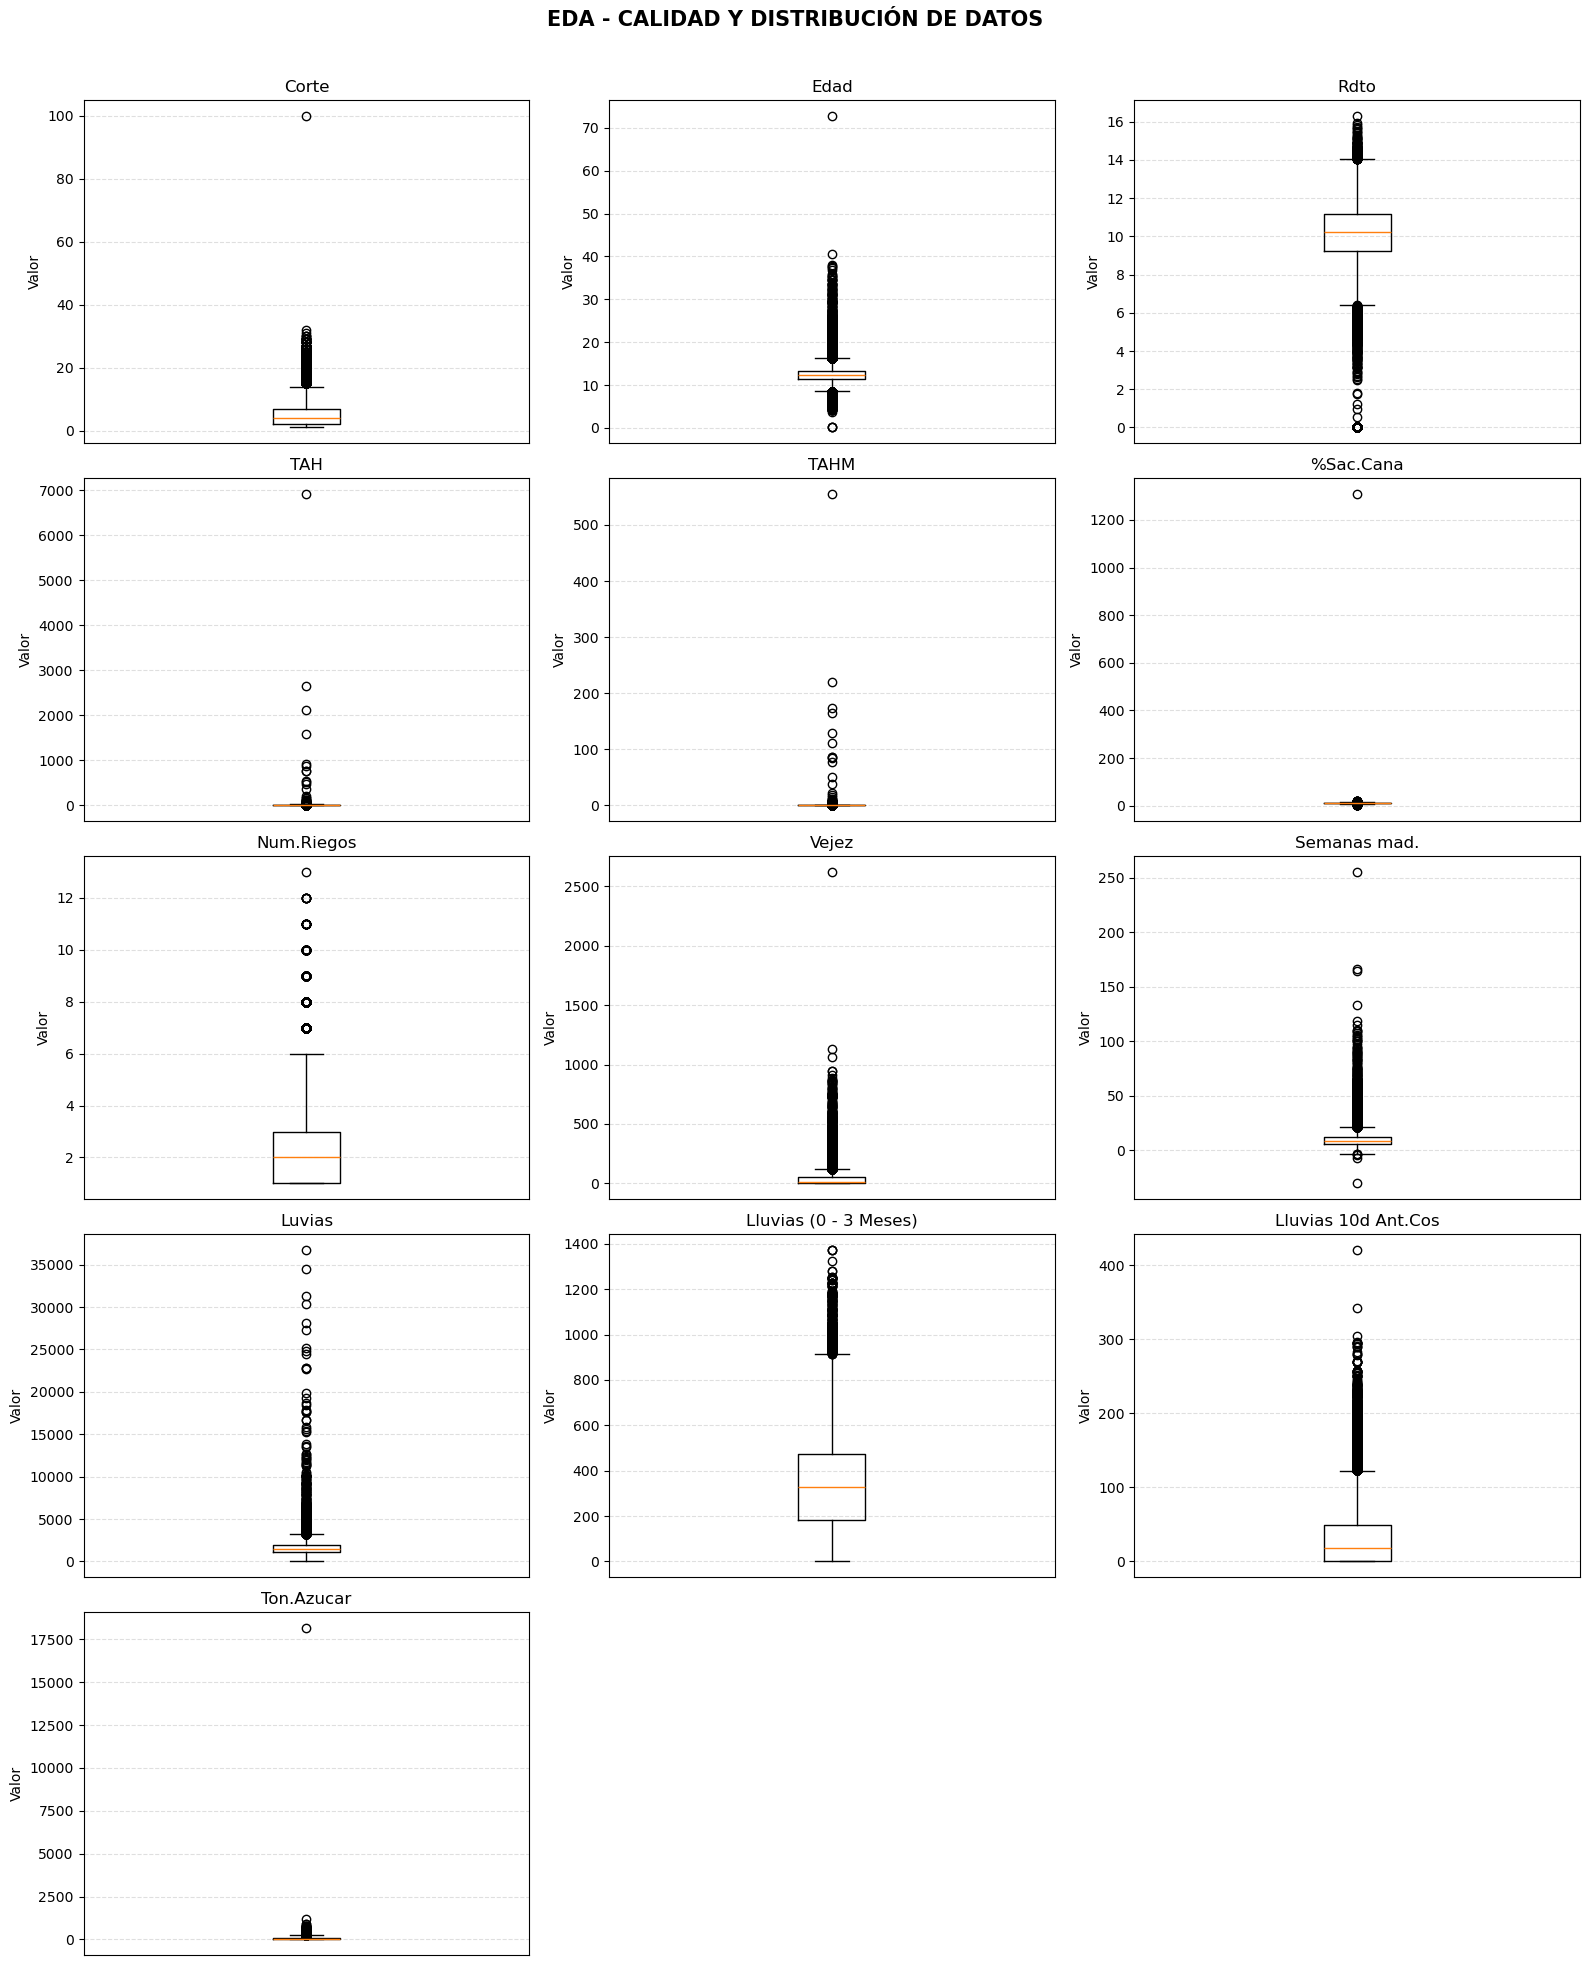


LÍMITES IQR Y VALORES CANDIDATOS A OUTLIERS
             Variable  Mín observado        Q1        Q3      IQR  Límite inferior IQR  Límite superior IQR  Candidatos inferiores  Candidatos superiores  Candidatos totales
                Corte         1.0000    2.0000    7.0000   5.0000              -5.5000              14.5000                      0                   3140                3140
                 Edad         0.1000   11.4000   13.3400   1.9400               8.4900              16.2500                   2268                   3285                5553
                 Rdto         0.0000    9.2527   11.1661   1.9134               6.3826              14.0362                   1609                    167                1776
                  TAH         0.0000    8.5657   13.3674   4.8017               1.3632              20.5700                   1017                    606                1623
                 TAHM         0.0000    0.6996    1.0673   0.3677               0.148

In [11]:
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# HU-39 Generar el reporte de calidad de datos   -   Paso 1:
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
import os
import math
import pandas as pd
import matplotlib.pyplot as plt


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 1. CONFIGURACIÓN
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

ARCHIVO_EXCEL = "/lakehouse/default/Files/data_historica/Reporte_Biosal.xlsx"
HOJA_EXCEL = "Data_original"

FACTOR_IQR = 1.5

VARIABLES_EDA = [
    "Variedad_TIFF",
    "Corte",
    "Edad",
    "Rdto",
    "TAH",
    "TAHM",
    "%Sac.Cana",
    "Num.Riegos",
    "Vejez",
    "Semanas mad.",
    "Luvias",
    "Lluvias (0 - 3 Meses)",
    "Lluvias 10d Ant.Cos",
    "Ton.Azucar",
]

# Variedad_TIFF es categórica y no se evalúa con IQR.
VARIABLES_IQR = [
    col for col in VARIABLES_EDA
    if col != "Variedad_TIFF"
]

COLUMNAS_TEXTO = [
    "Llave",
    "Periodos",
    "Archivo_origen",
    "Periodo",
    "CODSIA",
    "Hacienda",
    "Suerte",
    "Poligono",
    "Capa_producto_final",
    "Nombre",
    "Zona",
    "G.Tenencia",
    "Tenencia",
]


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 2. FUNCIONES AUXILIARES
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

def convertir_analisis_numerico(serie):
    """
    Convierte temporalmente una serie a valores numéricos.
    No modifica la columna original del DataFrame.
    """
    return pd.to_numeric(serie, errors="coerce")


def calcular_eda(df):
    """
    Calcula estadísticas descriptivas para cada variable.
    Variedad_TIFF se trata como categórica.
    """
    resultados = []
    total = len(df)

    for col in VARIABLES_EDA:

        serie_original = df[col]

        no_vacios = int(serie_original.notna().sum())
        vacios = int(serie_original.isna().sum())

        if col == "Variedad_TIFF":

            valores = serie_original.dropna()

            resultados.append({
                "Variable": col,
                "Tipo": "Cat",
                "Registros": total,
                "No vacíos": no_vacios,
                "Vacíos": vacios,
                "% vacíos": (
                    vacios / total * 100 if total else 0
                ),
                "Únicos": valores.nunique(),
                "No numéricos": "",
                "Media": "",
                "Mediana": "",
                "Desv. est.": "",
                "Mín": "",
                "P25": "",
                "P75": "",
                "Máx": "",
            })

            continue

        numerica = convertir_analisis_numerico(
            serie_original
        )

        no_numericos = int(
            (
                serie_original.notna()
                & numerica.isna()
            ).sum()
        )

        valores = numerica.dropna()

        if valores.empty:

            media = mediana = desviacion = None
            minimo = p25 = p75 = maximo = None
            unicos = 0

        else:

            media = valores.mean()
            mediana = valores.median()
            desviacion = valores.std()
            minimo = valores.min()
            p25 = valores.quantile(0.25)
            p75 = valores.quantile(0.75)
            maximo = valores.max()
            unicos = valores.nunique()

        resultados.append({
            "Variable": col,
            "Tipo": "Num",
            "Registros": total,
            "No vacíos": no_vacios,
            "Vacíos": vacios,
            "% vacíos": (
                vacios / total * 100 if total else 0
            ),
            "Únicos": unicos,
            "No numéricos": no_numericos,
            "Media": media,
            "Mediana": mediana,
            "Desv. est.": desviacion,
            "Mín": minimo,
            "P25": p25,
            "P75": p75,
            "Máx": maximo,
        })

    return pd.DataFrame(resultados)


def mostrar_eda(df, titulo):
    """
    Presenta la tabla EDA y los diagramas de caja y bigotes.
    No elimina ni modifica registros.
    """

    eda = calcular_eda(df)

    print("\n" + "=" * 110)
    print(titulo)
    print("=" * 110)

    with pd.option_context(
        "display.max_columns", None,
        "display.width", 240,
        "display.max_rows", None
    ):
        print(
            eda.round(4).to_string(index=False)
        )

    # --------------------------------------------------------
    # Diagramas de caja y bigotes
    # --------------------------------------------------------

    n = len(VARIABLES_IQR)
    columnas = 3
    filas = math.ceil(n / columnas)

    fig, axes = plt.subplots(
        filas,
        columnas,
        figsize=(16, 4 * filas)
    )

    axes = axes.flatten()

    for i, col in enumerate(VARIABLES_IQR):

        valores = convertir_analisis_numerico(
            df[col]
        ).dropna()

        if valores.empty:
            axes[i].set_title(f"{col} - Sin datos numéricos")
            axes[i].set_visible(True)
            continue

        axes[i].boxplot(
            valores,
            whis=FACTOR_IQR,
            showfliers=True
        )

        axes[i].set_title(col)
        axes[i].set_ylabel("Valor")
        axes[i].set_xticks([])

        axes[i].grid(
            axis="y",
            linestyle="--",
            alpha=0.4
        )

    for i in range(n, len(axes)):
        axes[i].set_visible(False)

    fig.suptitle(
        titulo,
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.97]
    )

    plt.show()

    return eda


def calcular_limites_iqr(df):
    """
    Calcula los límites estadísticos IQR y cuenta
    los valores que quedan fuera de ellos.

    No elimina ni modifica ningún registro.
    """

    resultados = []

    for col in VARIABLES_IQR:

        valores = convertir_analisis_numerico(
            df[col]
        ).dropna()

        if valores.empty:

            resultados.append({
                "Variable": col,
                "Mín observado": None,
                "Q1": None,
                "Q3": None,
                "IQR": None,
                "Límite inferior IQR": None,
                "Límite superior IQR": None,
                "Candidatos inferiores": 0,
                "Candidatos superiores": 0,
                "Candidatos totales": 0,
            })

            continue

        q1 = valores.quantile(0.25)
        q3 = valores.quantile(0.75)

        iqr = q3 - q1

        limite_inf = q1 - FACTOR_IQR * iqr
        limite_sup = q3 + FACTOR_IQR * iqr

        n_inf = int(
            (valores < limite_inf).sum()
        )

        n_sup = int(
            (valores > limite_sup).sum()
        )

        resultados.append({
            "Variable": col,
            "Mín observado": valores.min(),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Límite inferior IQR": limite_inf,
            "Límite superior IQR": limite_sup,
            "Candidatos inferiores": n_inf,
            "Candidatos superiores": n_sup,
            "Candidatos totales": n_inf + n_sup,
        })

    return pd.DataFrame(resultados)


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 3. CARGAR EL EXCEL
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

if not os.path.exists(ARCHIVO_EXCEL):
    raise FileNotFoundError(
        f"No se encontró el archivo:\n{ARCHIVO_EXCEL}"
    )

print("Cargando Excel...")

df = pd.read_excel(
    ARCHIVO_EXCEL,
    sheet_name=HOJA_EXCEL,
    dtype={
        col: "string"
        for col in COLUMNAS_TEXTO
    }
)

columnas_faltantes = [
    col for col in VARIABLES_EDA
    if col not in df.columns
]

if columnas_faltantes:
    raise ValueError(
        "Faltan variables requeridas en el Excel:\n"
        + "\n".join(columnas_faltantes)
    )

print(f"Registros cargados: {len(df):,}")
print(f"Columnas originales: {len(df.columns)}")


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 4. EDA: TABLA Y GRÁFICOS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

eda = mostrar_eda(
    df,
    "EDA - CALIDAD Y DISTRIBUCIÓN DE DATOS"
)


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 5. TABLA DE LÍMITES IQR Y CANDIDATOS A OUTLIERS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

tabla_iqr = calcular_limites_iqr(df)

print("\n" + "=" * 110)
print("LÍMITES IQR Y VALORES CANDIDATOS A OUTLIERS")
print("=" * 110)

with pd.option_context(
    "display.max_columns", None,
    "display.width", 240,
    "display.max_rows", None
):
    print(
        tabla_iqr.round(4).to_string(index=False)
    )

print("\nAnálisis terminado.")
print("No se eliminaron ni modificaron registros.")
print("El DataFrame original permanece disponible en la variable df.")


StatementMeta(, 6007d174-cf8f-43e7-82c4-69c3a49e361f, 21, Finished, Available, Finished, False)

CARGA DEL EXCEL ORIGINAL
Archivo: /lakehouse/default/Files/data_historica/Reporte_Biosal.xlsx
Hoja: Data_original
Registros originales: 60,693
Columnas originales: 79
Años encontrados: ['2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']

EDA INICIAL - ANTES DE DEPURAR VALORES


,Variable,Tipo,Registros,No vacíos,Vacíos,% vacíos,Únicos,No numéricos,Media,Mediana,Desv. est.,Mín,P25,P75,Máx
0,Variedad_TIFF,Cat,60693,60693,0,0.0000,58,,,,,,,,
1,Corte,Num,60693,60693,0,0.0000,33,0,5.306032,4.0,4.337781,1,2.0,7.0,100
2,Edad,Num,60693,60658,35,0.0577,712,0,12.477495,12.25,2.356969,0.1,11.4,13.34,72.8
3,Rdto,Num,60693,59857,836,1.3774,35586,0,10.048478,10.2471,1.929506,0.0,9.2527,11.1661,16.3071
4,TAH,Num,60693,60023,670,1.1039,57618,0,11.283781,11.021015,33.204612,0.0,8.565722,13.367414,6914.675
5,TAHM,Num,60693,59992,701,1.1550,57203,0,0.912522,0.891831,2.827094,0.0,0.69958,1.067265,555.395582
6,%Sac.Cana,Num,60693,58898,1795,2.9575,30449,0,11.898347,11.9309,5.541621,1.606,10.972325,12.8355,1309.0
7,Num.Riegos,Num,60693,20718,39975,65.8643,13,0,2.621682,2.0,1.694862,1.0,1.0,3.0,13.0
8,Vejez,Num,60693,59412,1281,2.1106,30928,0,36.318338,9.117,61.728572,0.0,2.099,50.5775,2619.83
9,Semanas mad.,Num,60693,26491,34202,56.3525,511,0,10.672498,8.714285,8.938347,-30.285714,6.142857,12.285714,255.285714


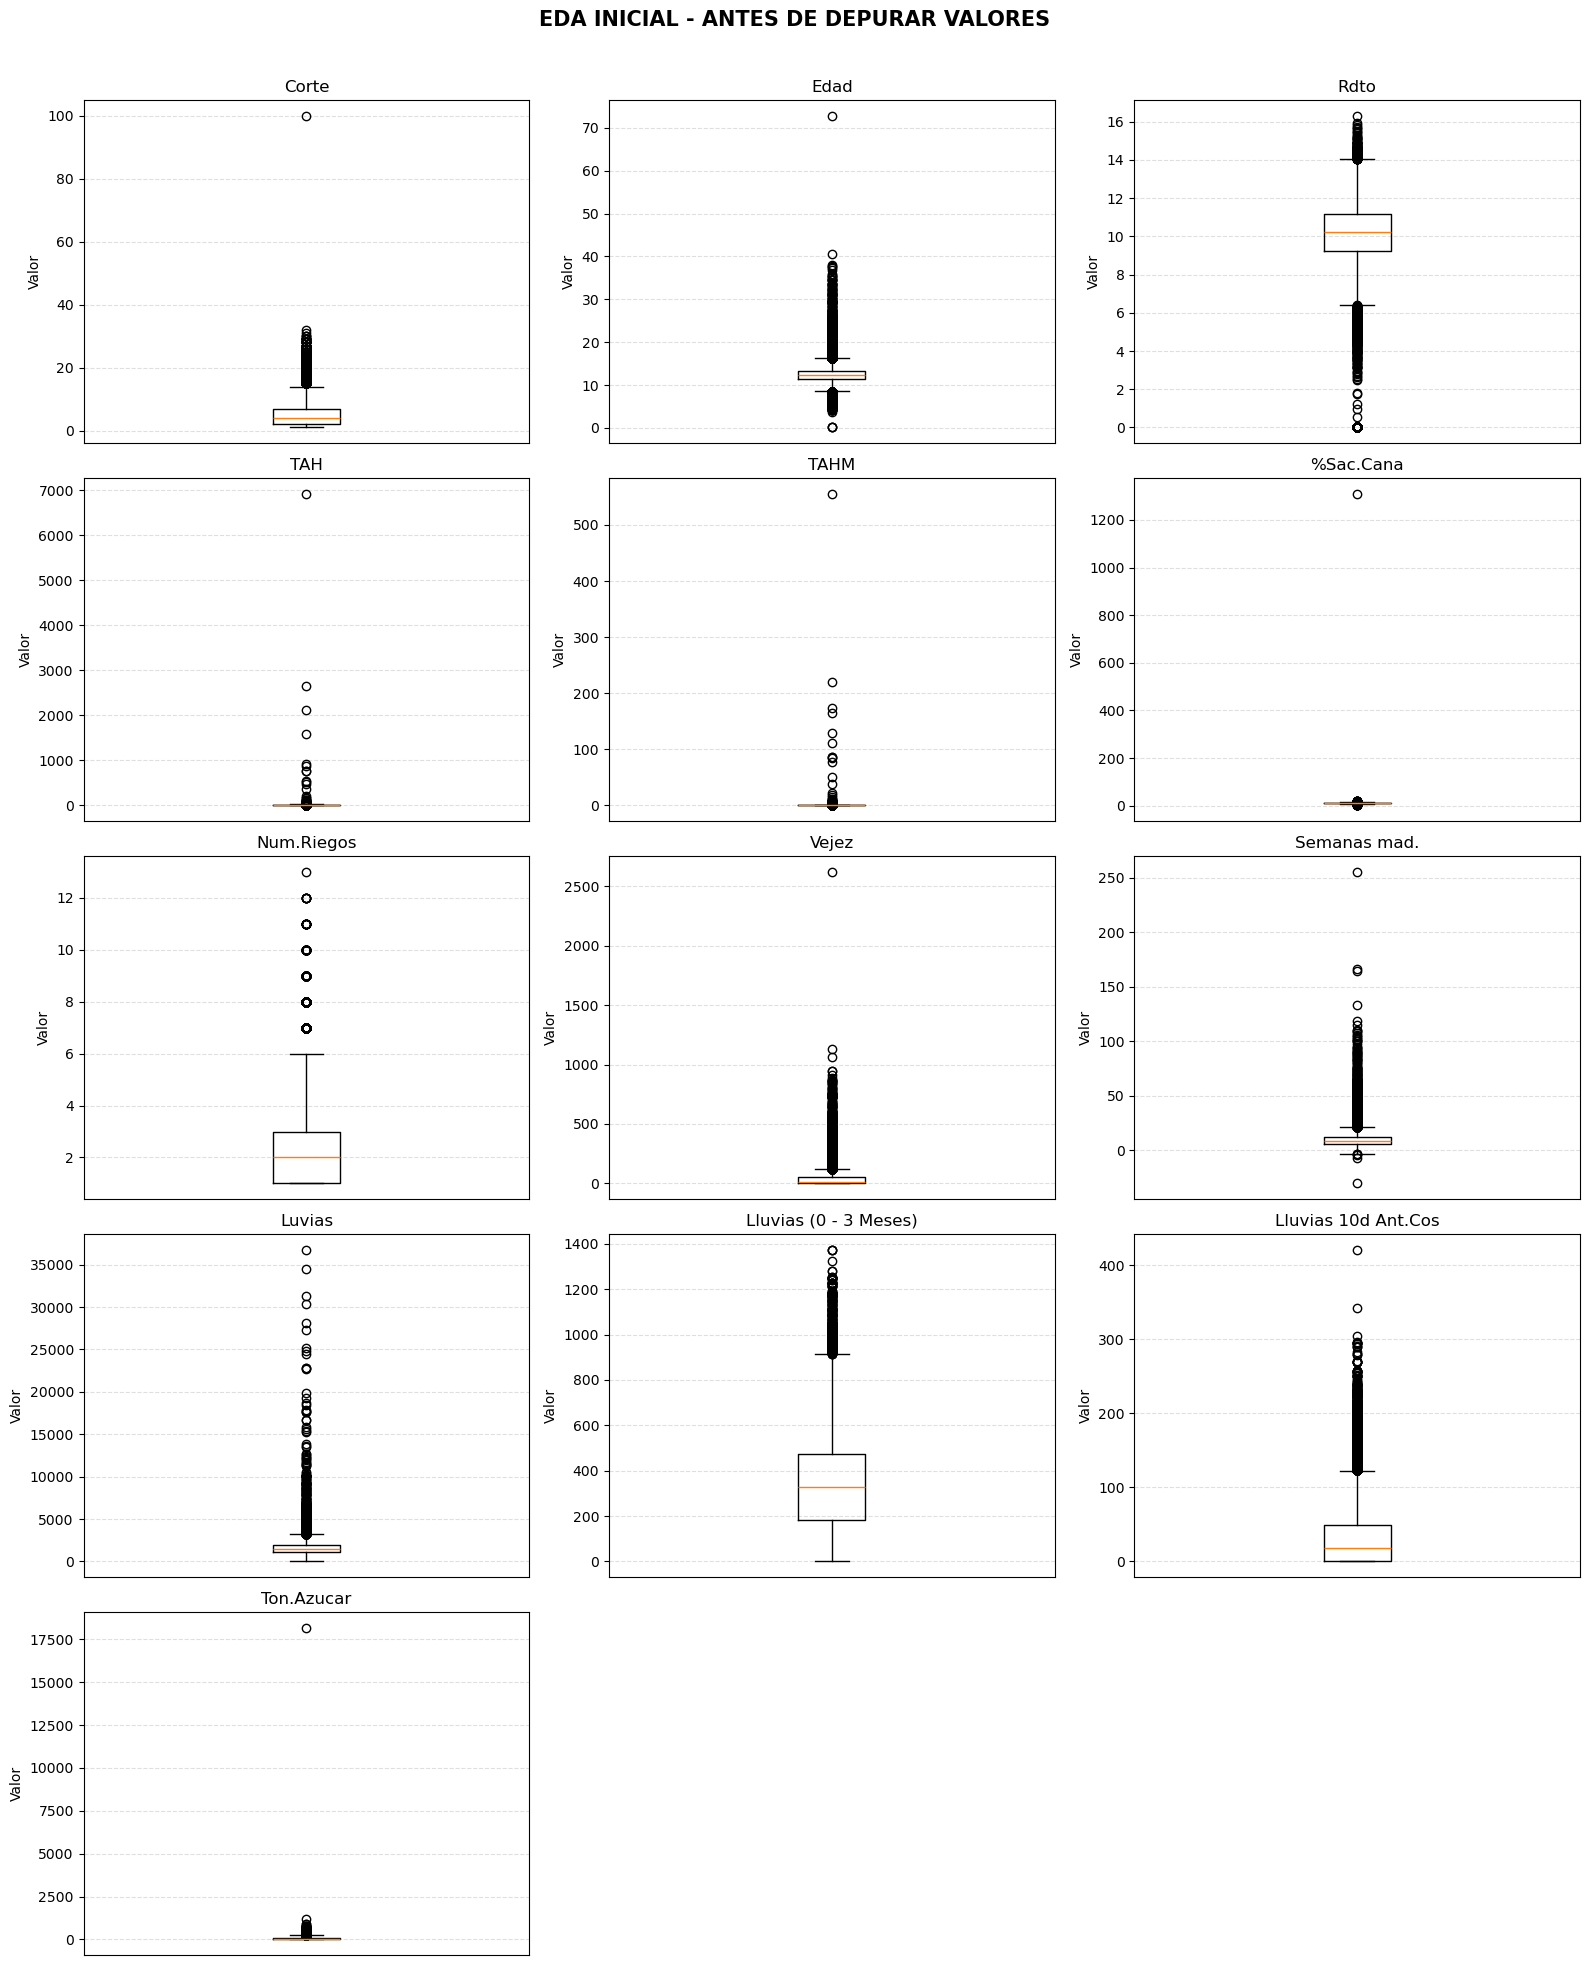


LÍMITES IQR INICIALES


,Variable,Q1,Q3,IQR,Límite inferior IQR,Límite superior IQR,Candidatos inferiores IQR,Candidatos superiores IQR,Candidatos totales IQR
0,Corte,2.0000,7.0000,5.0000,-5.5000,14.5000,0,3140,3140
1,Edad,11.4000,13.3400,1.9400,8.4900,16.2500,2268,3285,5553
2,Rdto,9.2527,11.1661,1.9134,6.3826,14.0362,1609,167,1776
3,TAH,8.5657,13.3674,4.8017,1.3632,20.5700,1017,606,1623
4,TAHM,0.6996,1.0673,0.3677,0.1481,1.6188,1033,553,1586
5,%Sac.Cana,10.9723,12.8355,1.8632,8.1776,15.6303,702,283,985
6,Num.Riegos,1.0000,3.0000,2.0000,-2.0000,6.0000,0,701,701
7,Vejez,2.0990,50.5775,48.4785,-70.6187,123.2952,0,3537,3537
8,Semanas mad.,6.1429,12.2857,6.1429,-3.0714,21.5000,5,1946,1951
9,Luvias,1069.0000,1931.0000,862.0000,-224.0000,3224.0000,0,1284,1284



VALORES QUE SE EXCLUIRÁN POR VARIABLE


,Variable,Minimo_permitido,Maximo_permitido,Minimo_observado,Maximo_observado,Valores_bajo_minimo,Valores_sobre_maximo,Total_fuera_rango_original,Minimo_fuera_rango,Maximo_fuera_rango
0,Corte,0,100,1.0000,100.0000,0,0,0,NaN,NaN
1,Edad,5,40,0.1000,72.8000,22,2,24,0.1000,72.8000
2,Rdto,3,17,0.0000,16.3071,942,0,942,0.0000,2.9386
3,TAH,0,100,0.0000,6914.6750,0,19,19,102.9167,6914.6750
4,TAHM,0,10,0.0000,555.3956,0,17,17,10.8415,555.3956
5,%Sac.Cana,0,100,1.6060,1309.0000,0,1,1,1309.0000,1309.0000
6,Num.Riegos,0,14,1.0000,13.0000,0,0,0,NaN,NaN
7,Vejez,0,2700,0.0000,2619.8300,0,0,0,NaN,NaN
8,Semanas mad.,0,80,-30.2857,255.2857,30,41,71,-30.2857,255.2857
9,Luvias,0,4500,0.0000,36733.8000,0,367,367,4501.0000,36733.8000


Corte                        | Inferiores:       0 | Superiores:       0 | Valores excluidos:       0
Edad                         | Inferiores:      22 | Superiores:       2 | Valores excluidos:      24
Rdto                         | Inferiores:     942 | Superiores:       0 | Valores excluidos:     942
TAH                          | Inferiores:       0 | Superiores:      19 | Valores excluidos:      19
TAHM                         | Inferiores:       0 | Superiores:      17 | Valores excluidos:      17
%Sac.Cana                    | Inferiores:       0 | Superiores:       1 | Valores excluidos:       1
Num.Riegos                   | Inferiores:       0 | Superiores:       0 | Valores excluidos:       0
Vejez                        | Inferiores:       0 | Superiores:       0 | Valores excluidos:       0
Semanas mad.                 | Inferiores:      30 | Superiores:      41 | Valores excluidos:      71
Luvias                       | Inferiores:       0 | Superiores:     367 | Valores

,Registros_originales,Registros_finales,Filas_eliminadas,Filas_con_algun_valor_atipico,Celdas_con_valores_excluidos,Porcentaje_filas_afectadas
0,60693,60693,0,1435,1511,2.36



DETALLE DE VALORES EXCLUIDOS POR VARIABLE


,Variable,Minimo_permitido,Maximo_permitido,Valores_inferiores_excluidos,Valores_superiores_excluidos,Total_valores_excluidos,Registros_originales,Registros_finales,Filas_eliminadas
0,Corte,0,100,0,0,0,60693,60693,0
1,Edad,5,40,22,2,24,60693,60693,0
2,Rdto,3,17,942,0,942,60693,60693,0
3,TAH,0,100,0,19,19,60693,60693,0
4,TAHM,0,10,0,17,17,60693,60693,0
5,%Sac.Cana,0,100,0,1,1,60693,60693,0
6,Num.Riegos,0,14,0,0,0,60693,60693,0
7,Vejez,0,2700,0,0,0,60693,60693,0
8,Semanas mad.,0,80,30,41,71,60693,60693,0
9,Luvias,0,4500,0,367,367,60693,60693,0



IMPORTANTE: el total de valores excluidos puede ser mayor que el total de filas afectadas, porque una misma fila puede contener valores atípicos en varias variables.

COMPARACIÓN DE REGISTROS POR AÑO


,year,Registros_antes,Registros_despues,Diferencia_registros
0,2014,5365,5365,0
1,2015,5783,5783,0
2,2016,5384,5384,0
3,2017,5260,5260,0
4,2018,5780,5780,0
5,2019,5324,5324,0
6,2020,5069,5069,0
7,2021,4503,4503,0
8,2022,4281,4281,0
9,2023,4402,4402,0


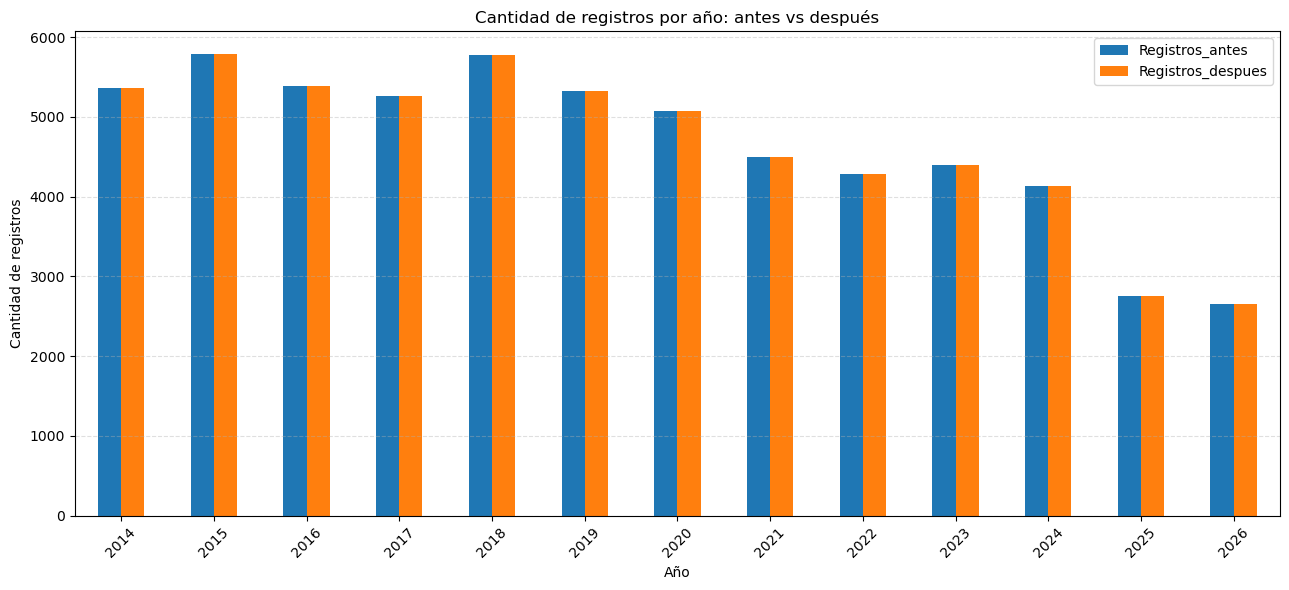

VERIFICACIÓN CORRECTA: se conservaron todos los registros de cada año.

EDA FINAL - DESPUÉS DE EXCLUIR VALORES ATÍPICOS


,Variable,Tipo,Registros,No vacíos,Vacíos,% vacíos,Únicos,No numéricos,Media,Mediana,Desv. est.,Mín,P25,P75,Máx
0,Variedad_TIFF,Cat,60693,60693,0,0.0000,58,,,,,,,,
1,Corte,Num,60693,60693,0,0.0000,33,0,5.306032,4.0,4.337781,1,2.0,7.0,100
2,Edad,Num,60693,60634,59,0.0972,691,0,12.479155,12.25,2.335958,5.09,11.4,13.34,37.95
3,Rdto,Num,60693,58915,1778,2.9295,35572,0,10.208669,10.2738,1.466555,3.0933,9.3086,11.18225,16.3071
4,TAH,Num,60693,60004,689,1.1352,57599,0,10.962203,11.019346,3.998157,0.0,8.564479,13.364789,95.461484
5,TAHM,Num,60693,59975,718,1.1830,57186,0,0.8818,0.891746,0.317962,0.0,0.69956,1.067064,10.0
6,%Sac.Cana,Num,60693,58897,1796,2.9592,30448,0,11.876324,11.9309,1.463816,1.606,10.9723,12.8355,20.25
7,Num.Riegos,Num,60693,20718,39975,65.8643,13,0,2.621682,2.0,1.694862,1.0,1.0,3.0,13.0
8,Vejez,Num,60693,59412,1281,2.1106,30928,0,36.318338,9.117,61.728572,0.0,2.099,50.5775,2619.83
9,Semanas mad.,Num,60693,26420,34273,56.4694,452,0,10.543403,8.714285,8.065906,0.0,6.142857,12.142857,80.0


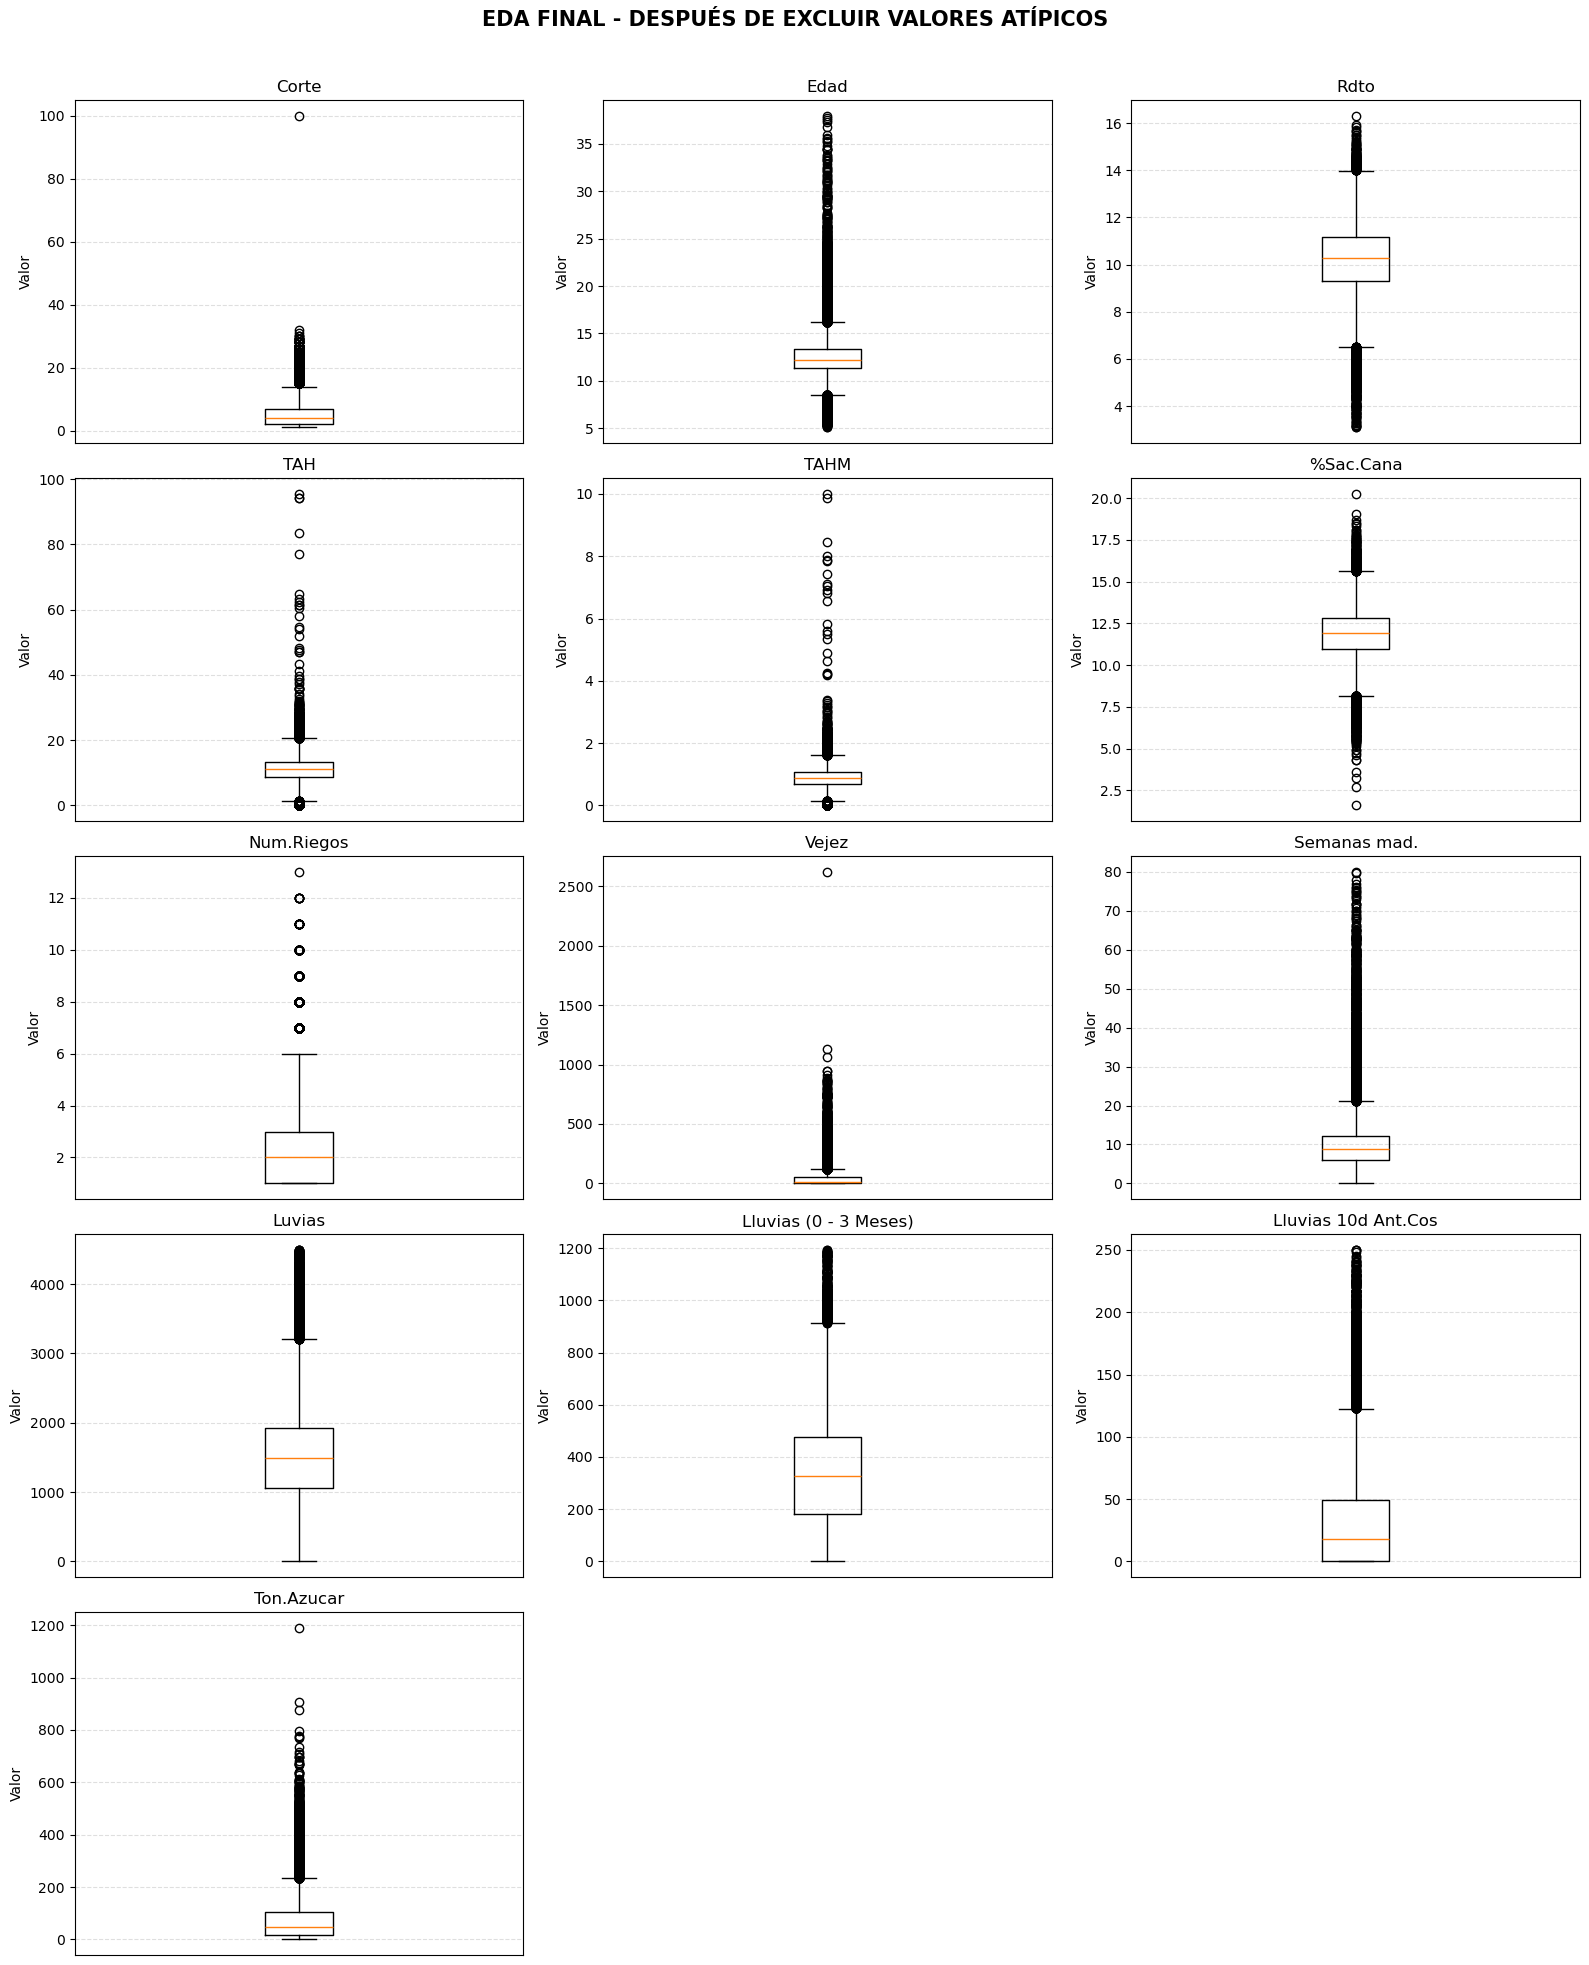


LÍMITES IQR DESPUÉS DE LA DEPURACIÓN


,Variable,Q1,Q3,IQR,Límite inferior IQR,Límite superior IQR,Candidatos inferiores IQR,Candidatos superiores IQR,Candidatos totales IQR
0,Corte,2.0000,7.0000,5.0000,-5.5000,14.5000,0,3140,3140
1,Edad,11.4000,13.3400,1.9400,8.4900,16.2500,2246,3283,5529
2,Rdto,9.3086,11.1822,1.8736,6.4981,13.9927,756,190,946
3,TAH,8.5645,13.3648,4.8003,1.3640,20.5653,1017,588,1605
4,TAHM,0.6996,1.0671,0.3675,0.1483,1.6183,1033,536,1569
5,%Sac.Cana,10.9723,12.8355,1.8632,8.1775,15.6303,702,282,984
6,Num.Riegos,1.0000,3.0000,2.0000,-2.0000,6.0000,0,701,701
7,Vejez,2.0990,50.5775,48.4785,-70.6187,123.2952,0,3537,3537
8,Semanas mad.,6.1429,12.1429,6.0000,-2.8571,21.1429,0,1957,1957
9,Luvias,1065.0000,1920.0000,855.0000,-217.5000,3202.5000,0,958,958



COMPARACIÓN EDA: ORIGINAL VS DEPURADO


,Variable,Tipo_Antes,Registros_Antes,No vacíos_Antes,Vacíos_Antes,% vacíos_Antes,Únicos_Antes,No numéricos_Antes,Media_Antes,Mediana_Antes,...,% vacíos_Despues,Únicos_Despues,No numéricos_Despues,Media_Despues,Mediana_Despues,Desv. est._Despues,Mín_Despues,P25_Despues,P75_Despues,Máx_Despues
0,Variedad_TIFF,Cat,60693,60693,0,0.0000,58,,,,...,0.0000,58,,,,,,,,
1,Corte,Num,60693,60693,0,0.0000,33,0,5.306032,4.0,...,0.0000,33,0,5.306032,4.0,4.337781,1,2.0,7.0,100
2,Edad,Num,60693,60658,35,0.0577,712,0,12.477495,12.25,...,0.0972,691,0,12.479155,12.25,2.335958,5.09,11.4,13.34,37.95
3,Rdto,Num,60693,59857,836,1.3774,35586,0,10.048478,10.2471,...,2.9295,35572,0,10.208669,10.2738,1.466555,3.0933,9.3086,11.18225,16.3071
4,TAH,Num,60693,60023,670,1.1039,57618,0,11.283781,11.021015,...,1.1352,57599,0,10.962203,11.019346,3.998157,0.0,8.564479,13.364789,95.461484
5,TAHM,Num,60693,59992,701,1.1550,57203,0,0.912522,0.891831,...,1.1830,57186,0,0.8818,0.891746,0.317962,0.0,0.69956,1.067064,10.0
6,%Sac.Cana,Num,60693,58898,1795,2.9575,30449,0,11.898347,11.9309,...,2.9592,30448,0,11.876324,11.9309,1.463816,1.606,10.9723,12.8355,20.25
7,Num.Riegos,Num,60693,20718,39975,65.8643,13,0,2.621682,2.0,...,65.8643,13,0,2.621682,2.0,1.694862,1.0,1.0,3.0,13.0
8,Vejez,Num,60693,59412,1281,2.1106,30928,0,36.318338,9.117,...,2.1106,30928,0,36.318338,9.117,61.728572,0.0,2.099,50.5775,2619.83
9,Semanas mad.,Num,60693,26491,34202,56.3525,511,0,10.672498,8.714285,...,56.4694,452,0,10.543403,8.714285,8.065906,0.0,6.142857,12.142857,80.0



COMPARACIÓN DE LÍMITES IQR


,Variable,Q1_Antes,Q3_Antes,IQR_Antes,Límite inferior IQR_Antes,Límite superior IQR_Antes,Candidatos inferiores IQR_Antes,Candidatos superiores IQR_Antes,Candidatos totales IQR_Antes,Q1_Despues,Q3_Despues,IQR_Despues,Límite inferior IQR_Despues,Límite superior IQR_Despues,Candidatos inferiores IQR_Despues,Candidatos superiores IQR_Despues,Candidatos totales IQR_Despues
0,Corte,2.0000,7.0000,5.0000,-5.5000,14.5000,0,3140,3140,2.0000,7.0000,5.0000,-5.5000,14.5000,0,3140,3140
1,Edad,11.4000,13.3400,1.9400,8.4900,16.2500,2268,3285,5553,11.4000,13.3400,1.9400,8.4900,16.2500,2246,3283,5529
2,Rdto,9.2527,11.1661,1.9134,6.3826,14.0362,1609,167,1776,9.3086,11.1822,1.8736,6.4981,13.9927,756,190,946
3,TAH,8.5657,13.3674,4.8017,1.3632,20.5700,1017,606,1623,8.5645,13.3648,4.8003,1.3640,20.5653,1017,588,1605
4,TAHM,0.6996,1.0673,0.3677,0.1481,1.6188,1033,553,1586,0.6996,1.0671,0.3675,0.1483,1.6183,1033,536,1569
5,%Sac.Cana,10.9723,12.8355,1.8632,8.1776,15.6303,702,283,985,10.9723,12.8355,1.8632,8.1775,15.6303,702,282,984
6,Num.Riegos,1.0000,3.0000,2.0000,-2.0000,6.0000,0,701,701,1.0000,3.0000,2.0000,-2.0000,6.0000,0,701,701
7,Vejez,2.0990,50.5775,48.4785,-70.6187,123.2952,0,3537,3537,2.0990,50.5775,48.4785,-70.6187,123.2952,0,3537,3537
8,Semanas mad.,6.1429,12.2857,6.1429,-3.0714,21.5000,5,1946,1951,6.1429,12.1429,6.0000,-2.8571,21.1429,0,1957,1957
9,Luvias,1069.0000,1931.0000,862.0000,-224.0000,3224.0000,0,1284,1284,1065.0000,1920.0000,855.0000,-217.5000,3202.5000,0,958,958


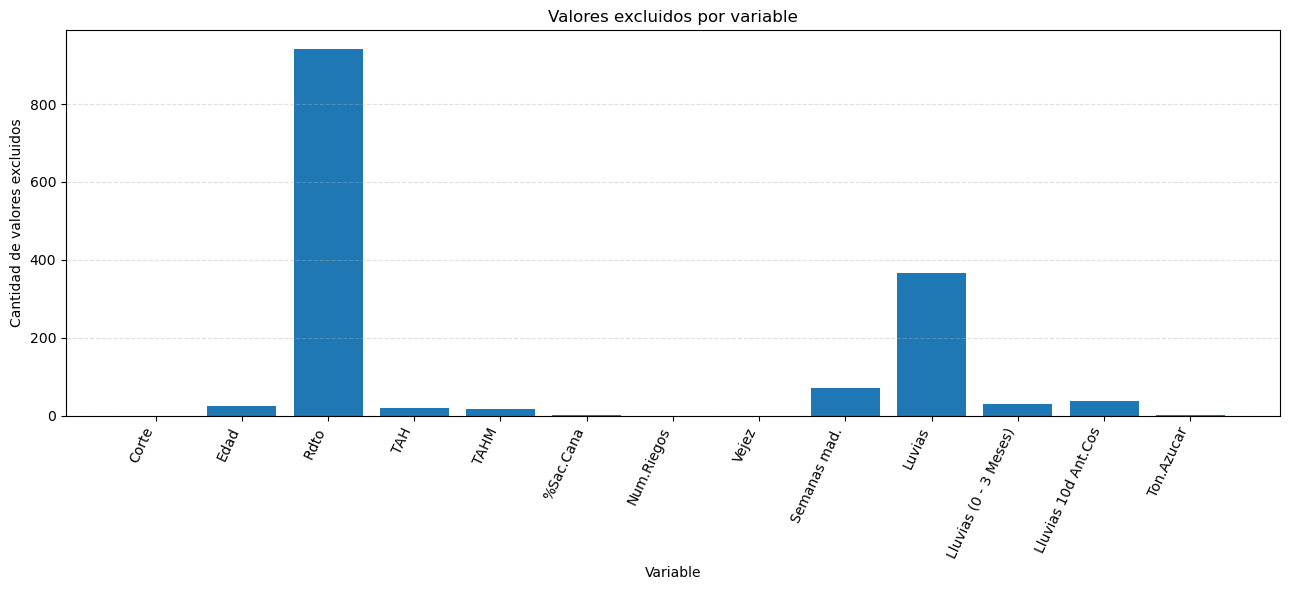

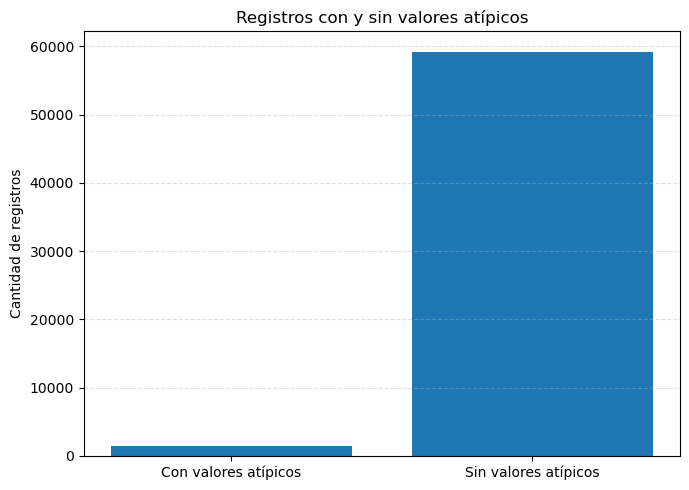


VERIFICACIONES FINALES
Registros originales: 60,693
Registros finales:    60,693
Filas eliminadas:     0
Filas con algún valor atípico: 1,435
Valores individuales excluidos: 1,511

CORRECTO: se conservaron todas las filas y sus índices originales.
Los valores fuera de rango se sustituyeron únicamente en sus respectivas columnas.

PROCESO FINALIZADO
Archivo de auditoría generado:
/lakehouse/default/Files/CONSOLIDADO/Auditoria_Valores_Atipicos.xlsx

DataFrames disponibles:
df_original_rangos          -> Excel original sin modificaciones
df_limpio_rangos            -> Datos con valores atípicos como NaN
df_resumen_general_rangos   -> Resumen general
df_resumen_rangos_original  -> Conteos fuera de rango por variable
df_historial_rangos         -> Resumen de depuración por variable
df_auditoria_atipicos       -> Detalle de cada valor excluido
df_resumen_anios_rangos     -> Comparación de filas por año
eda_comparativo_rangos      -> Comparación del EDA
iqr_comparativo_rangos      -> Compara

In [14]:
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# HU-39 Generar el reporte de calidad de datos   -   Paso 2:
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# DEPURACIÓN DE VALORES ATÍPICOS SIN ELIMINAR REGISTROS
# EDA INICIAL + LIMPIEZA POR VARIABLE + EDA FINAL
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
#
# OBJETIVO:
#   - Conservar todos los registros originales.
#   - Reemplazar únicamente los valores fuera de rango por NaN.
#   - Conservar el resto de los atributos de cada registro.
#   - Mostrar los EDA y gráficos antes y después.
#   - Comparar estadísticas, rangos y registros por año.
#   - Generar una auditoría de los valores excluidos.
#
# EJEMPLO:
#   Corte = 200 -> Corte pasa a NaN.
#   Edad, TAH, CODSIA y los demás campos se conservan.
#
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 1. CONFIGURACIÓN
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

ARCHIVO_EXCEL = "/lakehouse/default/Files/data_historica/Reporte_Biosal.xlsx"
HOJA_EXCEL = "Data_original"

FACTOR_IQR = 1.5

# Variables que se analizarán en el EDA.
VARIABLES_EDA = [
    "Variedad_TIFF",
    "Corte",
    "Edad",
    "Rdto",
    "TAH",
    "TAHM",
    "%Sac.Cana",
    "Num.Riegos",
    "Vejez",
    "Semanas mad.",
    "Luvias",
    "Lluvias (0 - 3 Meses)",
    "Lluvias 10d Ant.Cos",
    "Ton.Azucar",
]

# Variable categórica: no se le aplican límites numéricos.
VARIABLES_CATEGORICAS = [
    "Variedad_TIFF",
]

# Rangos permitidos definidos por ti.
# Los valores iguales a los límites se conservan.
RANGOS_DEPURACION = {
    "Corte": (0, 100),
    "Edad": (5, 40),
    "Rdto": (3, 17),
    "TAH": (0, 100),
    "TAHM": (0, 10),
    "%Sac.Cana": (0, 100),
    "Num.Riegos": (0, 14),
    "Vejez": (0, 2700),
    "Semanas mad.": (0, 80),
    "Luvias": (0, 4500),
    "Lluvias (0 - 3 Meses)": (0, 1200),
    "Lluvias 10d Ant.Cos": (0, 250),
    "Ton.Azucar": (0, 2300),
}

# Columnas que deben conservarse como texto.
COLUMNAS_TEXTO = [
    "Llave",
    "Periodos",
    "Archivo_origen",
    "Periodo",
    "CODSIA",
    "Hacienda",
    "Suerte",
    "Poligono",
    "Capa_producto_final",
    "Nombre",
    "Zona",
    "G.Tenencia",
    "Tenencia",
]

# Carpeta y archivo de resultados de auditoría.
#CARPETA_SALIDA = os.path.dirname(os.path.abspath(ARCHIVO_EXCEL))

# Carpeta CONSOLIDADO en Lakehouse Files para guardar la auditoría.
CARPETA_SALIDA = "/lakehouse/default/Files/CONSOLIDADO"

ARCHIVO_AUDITORIA = os.path.join(
    CARPETA_SALIDA,
    "Auditoria_Valores_Atipicos.xlsx"
)


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 2. FUNCIONES AUXILIARES
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

def convertir_analisis_numerico(serie):
    """
    Convierte temporalmente una serie a numérica para análisis.
    No modifica la serie original.
    Admite coma decimal.
    """

    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(
            serie,
            errors="coerce"
        )

    serie_texto = (
        serie.astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    return pd.to_numeric(
        serie_texto,
        errors="coerce"
    )


def calcular_eda(df):
    """
    Calcula estadísticas descriptivas de las variables EDA.
    Los vacíos se calculan sobre los valores originales.
    """

    resultados = []
    total = len(df)

    for col in VARIABLES_EDA:

        serie_original = df[col]

        no_vacios = int(serie_original.notna().sum())
        vacios = int(serie_original.isna().sum())

        if col in VARIABLES_CATEGORICAS:

            valores = serie_original.dropna()

            resultados.append({
                "Variable": col,
                "Tipo": "Cat",
                "Registros": total,
                "No vacíos": no_vacios,
                "Vacíos": vacios,
                "% vacíos": (
                    vacios / total * 100 if total else 0
                ),
                "Únicos": valores.nunique(),
                "No numéricos": "",
                "Media": "",
                "Mediana": "",
                "Desv. est.": "",
                "Mín": "",
                "P25": "",
                "P75": "",
                "Máx": "",
            })

            continue

        numerica = convertir_analisis_numerico(
            serie_original
        )

        no_numericos = int(
            (
                serie_original.notna()
                & numerica.isna()
            ).sum()
        )

        valores = numerica.dropna()

        if valores.empty:
            media = None
            mediana = None
            desviacion = None
            minimo = None
            p25 = None
            p75 = None
            maximo = None
            unicos = 0

        else:
            media = valores.mean()
            mediana = valores.median()
            desviacion = valores.std()
            minimo = valores.min()
            p25 = valores.quantile(0.25)
            p75 = valores.quantile(0.75)
            maximo = valores.max()
            unicos = valores.nunique()

        resultados.append({
            "Variable": col,
            "Tipo": "Num",
            "Registros": total,
            "No vacíos": no_vacios,
            "Vacíos": vacios,
            "% vacíos": (
                vacios / total * 100 if total else 0
            ),
            "Únicos": unicos,
            "No numéricos": no_numericos,
            "Media": media,
            "Mediana": mediana,
            "Desv. est.": desviacion,
            "Mín": minimo,
            "P25": p25,
            "P75": p75,
            "Máx": maximo,
        })

    return pd.DataFrame(resultados)


def calcular_limites_iqr(df):
    """
    Calcula los límites estadísticos IQR.
    No elimina ni modifica datos.
    """

    resultados = []

    for col in VARIABLES_EDA:

        if col in VARIABLES_CATEGORICAS:
            continue

        valores = convertir_analisis_numerico(
            df[col]
        ).dropna()

        if valores.empty:

            resultados.append({
                "Variable": col,
                "Q1": None,
                "Q3": None,
                "IQR": None,
                "Límite inferior IQR": None,
                "Límite superior IQR": None,
                "Candidatos inferiores IQR": 0,
                "Candidatos superiores IQR": 0,
                "Candidatos totales IQR": 0,
            })

            continue

        q1 = valores.quantile(0.25)
        q3 = valores.quantile(0.75)
        iqr = q3 - q1

        limite_inf = q1 - FACTOR_IQR * iqr
        limite_sup = q3 + FACTOR_IQR * iqr

        n_inf = int((valores < limite_inf).sum())
        n_sup = int((valores > limite_sup).sum())

        resultados.append({
            "Variable": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Límite inferior IQR": limite_inf,
            "Límite superior IQR": limite_sup,
            "Candidatos inferiores IQR": n_inf,
            "Candidatos superiores IQR": n_sup,
            "Candidatos totales IQR": n_inf + n_sup,
        })

    return pd.DataFrame(resultados)


def mostrar_eda(df, titulo):
    """
    Muestra la tabla EDA y los diagramas de caja y bigotes.
    """

    eda = calcular_eda(df)

    print("\n" + "=" * 110)
    print(titulo)
    print("=" * 110)

    display(eda.round(4))

    variables_numericas = [
        c for c in VARIABLES_EDA
        if c not in VARIABLES_CATEGORICAS
    ]

    columnas = 3
    filas = math.ceil(
        len(variables_numericas) / columnas
    )

    fig, axes = plt.subplots(
        filas,
        columnas,
        figsize=(16, 4 * filas)
    )

    axes = np.asarray(axes).flatten()

    for i, col in enumerate(variables_numericas):

        valores = convertir_analisis_numerico(
            df[col]
        ).dropna()

        if valores.empty:
            axes[i].set_title(f"{col} - Sin datos")
            axes[i].set_visible(True)
            continue

        axes[i].boxplot(
            valores,
            whis=FACTOR_IQR,
            showfliers=True
        )

        axes[i].set_title(col)
        axes[i].set_ylabel("Valor")
        axes[i].set_xticks([])
        axes[i].grid(
            axis="y",
            linestyle="--",
            alpha=0.4
        )

    for i in range(len(variables_numericas), len(axes)):
        axes[i].set_visible(False)

    fig.suptitle(
        titulo,
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

    return eda


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 3. CARGAR EXCEL ORIGINAL
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

if not os.path.exists(ARCHIVO_EXCEL):
    raise FileNotFoundError(
        f"No se encontró el archivo:\n{ARCHIVO_EXCEL}"
    )

print("=" * 100)
print("CARGA DEL EXCEL ORIGINAL")
print("=" * 100)

df_original_rangos = pd.read_excel(
    ARCHIVO_EXCEL,
    sheet_name=HOJA_EXCEL,
    dtype={
        col: "string"
        for col in COLUMNAS_TEXTO
    }
).reset_index(drop=True)

# Identificador permanente para relacionar la auditoría
# con la fila original del Excel.
df_original_rangos.index.name = "Indice_original"

# Guardamos el original y no lo modificamos.
df_original_rangos = df_original_rangos.copy(deep=True)

columnas_faltantes = [
    col for col in VARIABLES_EDA
    if col not in df_original_rangos.columns
]

if columnas_faltantes:
    raise ValueError(
        "Faltan variables EDA en el Excel:\n"
        + "\n".join(columnas_faltantes)
    )

columnas_rango_faltantes = [
    col for col in RANGOS_DEPURACION
    if col not in df_original_rangos.columns
]

if columnas_rango_faltantes:
    raise ValueError(
        "Faltan variables con rangos definidos:\n"
        + "\n".join(columnas_rango_faltantes)
    )

TOTAL_ORIGINAL = len(df_original_rangos)

if TOTAL_ORIGINAL == 0:
    raise ValueError("El Excel no contiene registros.")

print(f"Archivo: {ARCHIVO_EXCEL}")
print(f"Hoja: {HOJA_EXCEL}")
print(f"Registros originales: {TOTAL_ORIGINAL:,}")
print(f"Columnas originales: {len(df_original_rangos.columns)}")

if "year" in df_original_rangos.columns:
    print(
        "Años encontrados:",
        sorted(
            df_original_rangos["year"]
            .dropna()
            .astype(str)
            .unique()
            .tolist()
        )
    )


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 4. EDA INICIAL Y GRÁFICOS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

eda_antes_rangos = mostrar_eda(
    df_original_rangos,
    "EDA INICIAL - ANTES DE DEPURAR VALORES"
)

iqr_antes_rangos = calcular_limites_iqr(
    df_original_rangos
)

print("\nLÍMITES IQR INICIALES")
display(iqr_antes_rangos.round(4))


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 5. IDENTIFICAR VALORES FUERA DE LOS RANGOS DEFINIDOS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

resumen_inicial = []
mascaras_originales = {}

for variable, (minimo, maximo) in RANGOS_DEPURACION.items():

    valores = convertir_analisis_numerico(
        df_original_rangos[variable]
    )

    mascara_inferior = (
        valores.notna()
        & (valores < minimo)
    )

    mascara_superior = (
        valores.notna()
        & (valores > maximo)
    )

    mascara_fuera = (
        mascara_inferior
        | mascara_superior
    )

    mascaras_originales[variable] = mascara_fuera

    valores_fuera = valores[mascara_fuera]

    resumen_inicial.append({
        "Variable": variable,
        "Minimo_permitido": minimo,
        "Maximo_permitido": maximo,
        "Minimo_observado": valores.min(),
        "Maximo_observado": valores.max(),
        "Valores_bajo_minimo": int(mascara_inferior.sum()),
        "Valores_sobre_maximo": int(mascara_superior.sum()),
        "Total_fuera_rango_original": int(mascara_fuera.sum()),
        "Minimo_fuera_rango": (
            valores_fuera.min()
            if not valores_fuera.empty else np.nan
        ),
        "Maximo_fuera_rango": (
            valores_fuera.max()
            if not valores_fuera.empty else np.nan
        ),
    })

df_resumen_rangos_original = pd.DataFrame(
    resumen_inicial
)

print("\n" + "=" * 110)
print("VALORES QUE SE EXCLUIRÁN POR VARIABLE")
print("=" * 110)

display(df_resumen_rangos_original.round(4))


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 6. COPIAR EL DATAFRAME Y REEMPLAZAR SOLO VALORES ATÍPICOS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
#
# IMPORTANTE:
#   NO se elimina ninguna fila.
#   Solo se reemplaza el valor fuera de rango por NaN.
#   Las demás columnas de esa fila permanecen intactas.
#
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

df_limpio_rangos = df_original_rangos.copy(deep=True)

auditoria_valores = []
historial_rangos = []

for variable, (minimo, maximo) in RANGOS_DEPURACION.items():

    valores_numericos = convertir_analisis_numerico(
        df_original_rangos[variable]
    )

    mascara_inferior = (
        valores_numericos.notna()
        & (valores_numericos < minimo)
    )

    mascara_superior = (
        valores_numericos.notna()
        & (valores_numericos > maximo)
    )

    mascara_fuera = (
        mascara_inferior
        | mascara_superior
    )

    indices_fuera = df_original_rangos.index[
        mascara_fuera
    ]

    cantidad_inferior = int(mascara_inferior.sum())
    cantidad_superior = int(mascara_superior.sum())
    cantidad_fuera = int(mascara_fuera.sum())

    # --------------------------------------------------------
    # AUDITORÍA: registrar cada valor que será invalidado.
    # --------------------------------------------------------

    for indice in indices_fuera:

        registro = {
            "Indice_original": indice,
            "Variable": variable,
            "Valor_original": df_original_rangos.at[
                indice, variable
            ],
            "Valor_numerico_analizado": valores_numericos.loc[
                indice
            ],
            "Minimo_permitido": minimo,
            "Maximo_permitido": maximo,
            "Motivo": (
                "Inferior al mínimo"
                if valores_numericos.loc[indice] < minimo
                else "Superior al máximo"
            ),
        }

        # Agregar identificadores disponibles para facilitar
        # la localización del registro en el Excel.
        for columna in [
            "Llave",
            "year",
            "Periodos",
            "Periodo",
            "CODSIA",
            "Hacienda",
            "Suerte",
            "Capa_producto_final",
        ]:
            if columna in df_original_rangos.columns:
                registro[columna] = (
                    df_original_rangos.at[indice, columna]
                )

        auditoria_valores.append(registro)

    # --------------------------------------------------------
    # DEPURACIÓN: solo la celda fuera de rango se vuelve NaN.
    # --------------------------------------------------------

    if cantidad_fuera > 0:

        df_limpio_rangos.loc[
            mascara_fuera,
            variable
        ] = np.nan

    # --------------------------------------------------------
    # HISTORIAL POR VARIABLE
    # --------------------------------------------------------

    historial_rangos.append({
        "Variable": variable,
        "Minimo_permitido": minimo,
        "Maximo_permitido": maximo,
        "Valores_inferiores_excluidos": cantidad_inferior,
        "Valores_superiores_excluidos": cantidad_superior,
        "Total_valores_excluidos": cantidad_fuera,
        "Registros_originales": TOTAL_ORIGINAL,
        "Registros_finales": len(df_limpio_rangos),
        "Filas_eliminadas": 0,
    })

    print(
        f"{variable:28s} | "
        f"Inferiores: {cantidad_inferior:>7,} | "
        f"Superiores: {cantidad_superior:>7,} | "
        f"Valores excluidos: {cantidad_fuera:>7,}"
    )

df_historial_rangos = pd.DataFrame(
    historial_rangos
)

if auditoria_valores:
    df_auditoria_atipicos = pd.DataFrame(
        auditoria_valores
    )
else:
    df_auditoria_atipicos = pd.DataFrame(
        columns=[
            "Indice_original",
            "Variable",
            "Valor_original",
            "Valor_numerico_analizado",
            "Minimo_permitido",
            "Maximo_permitido",
            "Motivo",
        ]
    )


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 7. RESUMEN GENERAL DE LA DEPURACIÓN
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

TOTAL_FINAL = len(df_limpio_rangos)

# Conteo de celdas fuera de rango, no de filas.
TOTAL_VALORES_EXCLUIDOS = int(
    df_historial_rangos["Total_valores_excluidos"].sum()
)

# Una misma fila puede tener varios valores excluidos.
# Por eso el número de valores excluidos no representa
# el número de registros eliminados.

mascara_fila_afectada = pd.Series(
    False,
    index=df_original_rangos.index
)

for mascara in mascaras_originales.values():
    mascara_fila_afectada |= mascara

TOTAL_FILAS_AFECTADAS = int(
    mascara_fila_afectada.sum()
)

df_resumen_general_rangos = pd.DataFrame([{
    "Registros_originales": TOTAL_ORIGINAL,
    "Registros_finales": TOTAL_FINAL,
    "Filas_eliminadas": TOTAL_ORIGINAL - TOTAL_FINAL,
    "Filas_con_algun_valor_atipico": TOTAL_FILAS_AFECTADAS,
    "Celdas_con_valores_excluidos": TOTAL_VALORES_EXCLUIDOS,
    "Porcentaje_filas_afectadas": (
        TOTAL_FILAS_AFECTADAS / TOTAL_ORIGINAL * 100
        if TOTAL_ORIGINAL else 0
    ),
}])

print("\n" + "=" * 110)
print("RESUMEN GENERAL DE DEPURACIÓN")
print("=" * 110)

display(df_resumen_general_rangos.round(2))

print("\nDETALLE DE VALORES EXCLUIDOS POR VARIABLE")
display(df_historial_rangos)

print(
    "\nIMPORTANTE: el total de valores excluidos puede ser "
    "mayor que el total de filas afectadas, porque una misma "
    "fila puede contener valores atípicos en varias variables."
)


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 8. COMPARACIÓN DE REGISTROS POR AÑO
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
#
# Como no se eliminan filas, los conteos por año deben
# mantenerse exactamente iguales.
#
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

if "year" in df_original_rangos.columns:

    antes_anio = (
        df_original_rangos.groupby(
            "year",
            dropna=False
        )
        .size()
        .rename("Registros_antes")
    )

    despues_anio = (
        df_limpio_rangos.groupby(
            "year",
            dropna=False
        )
        .size()
        .rename("Registros_despues")
    )

    df_resumen_anios_rangos = pd.concat(
        [
            antes_anio,
            despues_anio
        ],
        axis=1
    ).fillna(0)

    df_resumen_anios_rangos = (
        df_resumen_anios_rangos
        .astype(int)
        .reset_index()
    )

    df_resumen_anios_rangos[
        "Diferencia_registros"
    ] = (
        df_resumen_anios_rangos["Registros_antes"]
        - df_resumen_anios_rangos["Registros_despues"]
    )

    print("\n" + "=" * 110)
    print("COMPARACIÓN DE REGISTROS POR AÑO")
    print("=" * 110)

    display(df_resumen_anios_rangos)

    ax = df_resumen_anios_rangos.plot(
        x="year",
        y=[
            "Registros_antes",
            "Registros_despues",
        ],
        kind="bar",
        figsize=(13, 6)
    )

    ax.set_title(
        "Cantidad de registros por año: antes vs después"
    )

    ax.set_xlabel("Año")
    ax.set_ylabel("Cantidad de registros")
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Comprobación automática.
    if (
        df_resumen_anios_rangos[
            "Diferencia_registros"
        ] == 0
    ).all():
        print(
            "VERIFICACIÓN CORRECTA: se conservaron "
            "todos los registros de cada año."
        )
    else:
        print(
            "ADVERTENCIA: se detectó una diferencia "
            "en los conteos por año."
        )

else:
    df_resumen_anios_rangos = pd.DataFrame()

    print(
        "No existe la columna 'year'; "
        "no se puede generar la comparación por año."
    )


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 9. EDA FINAL Y GRÁFICOS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

eda_despues_rangos = mostrar_eda(
    df_limpio_rangos,
    "EDA FINAL - DESPUÉS DE EXCLUIR VALORES ATÍPICOS"
)

iqr_despues_rangos = calcular_limites_iqr(
    df_limpio_rangos
)

print("\nLÍMITES IQR DESPUÉS DE LA DEPURACIÓN")
display(iqr_despues_rangos.round(4))


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 10. COMPARACIÓN EDA INICIAL VS FINAL
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

eda_comparativo_rangos = eda_antes_rangos.merge(
    eda_despues_rangos,
    on="Variable",
    how="outer",
    suffixes=("_Antes", "_Despues")
)

print("\n" + "=" * 110)
print("COMPARACIÓN EDA: ORIGINAL VS DEPURADO")
print("=" * 110)

display(eda_comparativo_rangos.round(4))


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 11. COMPARACIÓN IQR INICIAL VS FINAL
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

iqr_comparativo_rangos = iqr_antes_rangos.merge(
    iqr_despues_rangos,
    on="Variable",
    how="outer",
    suffixes=("_Antes", "_Despues")
)

print("\n" + "=" * 110)
print("COMPARACIÓN DE LÍMITES IQR")
print("=" * 110)

display(iqr_comparativo_rangos.round(4))


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 12. GRÁFICO DE VALORES EXCLUIDOS POR VARIABLE
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

plt.figure(figsize=(13, 6))

plt.bar(
    df_historial_rangos["Variable"],
    df_historial_rangos["Total_valores_excluidos"]
)

plt.title("Valores excluidos por variable")
plt.xlabel("Variable")
plt.ylabel("Cantidad de valores excluidos")

plt.xticks(
    rotation=65,
    ha="right"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 13. GRÁFICO DE FILAS AFECTADAS VS NO AFECTADAS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

filas_no_afectadas = (
    TOTAL_ORIGINAL - TOTAL_FILAS_AFECTADAS
)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Con valores atípicos", "Sin valores atípicos"],
    [
        TOTAL_FILAS_AFECTADAS,
        filas_no_afectadas,
    ]
)

plt.title("Registros con y sin valores atípicos")
plt.ylabel("Cantidad de registros")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 14. VERIFICACIONES FINALES
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

print("\n" + "=" * 110)
print("VERIFICACIONES FINALES")
print("=" * 110)

print(f"Registros originales: {TOTAL_ORIGINAL:,}")
print(f"Registros finales:    {TOTAL_FINAL:,}")
print(
    f"Filas eliminadas:     "
    f"{TOTAL_ORIGINAL - TOTAL_FINAL:,}"
)
print(
    f"Filas con algún valor atípico: "
    f"{TOTAL_FILAS_AFECTADAS:,}"
)
print(
    f"Valores individuales excluidos: "
    f"{TOTAL_VALORES_EXCLUIDOS:,}"
)

assert TOTAL_ORIGINAL == TOTAL_FINAL, (
    "ERROR: el número de filas cambió."
)

assert df_original_rangos.index.equals(
    df_limpio_rangos.index
), "ERROR: los índices de las filas no coinciden."

print(
    "\nCORRECTO: se conservaron todas las filas "
    "y sus índices originales."
)

print(
    "Los valores fuera de rango se sustituyeron "
    "únicamente en sus respectivas columnas."
)


#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+
# 15. EXPORTAR AUDITORÍA Y RESULTADOS
#+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+

with pd.ExcelWriter(
    ARCHIVO_AUDITORIA,
    engine="openpyxl"
) as writer:

    df_limpio_rangos.to_excel(
        writer,
        sheet_name="Datos_Depurados",
        index=False
    )

    df_resumen_general_rangos.to_excel(
        writer,
        sheet_name="Resumen_General",
        index=False
    )

    df_resumen_rangos_original.to_excel(
        writer,
        sheet_name="Valores_Fuera_Rango",
        index=False
    )

    df_historial_rangos.to_excel(
        writer,
        sheet_name="Resumen_por_Variable",
        index=False
    )

    df_auditoria_atipicos.to_excel(
        writer,
        sheet_name="Auditoria_Detallada",
        index=False
    )

    df_resumen_anios_rangos.to_excel(
        writer,
        sheet_name="Resumen_por_Anio",
        index=False
    )

    eda_antes_rangos.to_excel(
        writer,
        sheet_name="EDA_Inicial",
        index=False
    )

    eda_despues_rangos.to_excel(
        writer,
        sheet_name="EDA_Final",
        index=False
    )

    eda_comparativo_rangos.to_excel(
        writer,
        sheet_name="Comparacion_EDA",
        index=False
    )

    iqr_comparativo_rangos.to_excel(
        writer,
        sheet_name="Comparacion_IQR",
        index=False
    )

print("\n" + "=" * 110)
print("PROCESO FINALIZADO")
print("=" * 110)

print(f"Archivo de auditoría generado:\n{ARCHIVO_AUDITORIA}")

print("\nDataFrames disponibles:")
print("df_original_rangos          -> Excel original sin modificaciones")
print("df_limpio_rangos            -> Datos con valores atípicos como NaN")
print("df_resumen_general_rangos   -> Resumen general")
print("df_resumen_rangos_original  -> Conteos fuera de rango por variable")
print("df_historial_rangos         -> Resumen de depuración por variable")
print("df_auditoria_atipicos       -> Detalle de cada valor excluido")
print("df_resumen_anios_rangos     -> Comparación de filas por año")
print("eda_comparativo_rangos      -> Comparación del EDA")
print("iqr_comparativo_rangos      -> Comparación de límites IQR")